# Classification Track — Telco Customer Churn (Part B + Consolidated Comparison)
**23CSE301 Machine Learning Capstone — Review 2**

**Dataset:** `data/telco_churn.csv` | **Target:** `Churn` (Yes/No) — binary classification.

This notebook continues from Part A (`classification.ipynb`). It covers:
1. Re-creating the **identical** cleaning, feature engineering, stratified 80:20 split and preprocessor used in Part A (`random_state=42`), so every model is compared on the same test set.
2. **Part B algorithms:** Random Forest, AdaBoost, Gradient Boosting, Bagging (Decision Tree base), MLP.
3. The **consolidated 10-algorithm comparison table** (Accuracy, Precision, Recall, F1, ROC-AUC) — deliverable D6 / rubric A2.
4. **5-fold cross-validation** for the two best models, **hyperparameter tuning**, and **final model selection** with justification (rubric A3).

## 0. Imports & Setup

In [6]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Part A models (re-trained here so the consolidated table is produced in one place)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

# Part B models
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, BaggingClassifier)
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay,
    classification_report
)

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams['figure.dpi'] = 100


## 1. Data Loading & Preprocessing (identical to Part A)
Same cleaning, engineered feature (`NumServices`), stratified split and preprocessor as Part A.
Scaler and encoder live inside the `ColumnTransformer`, which sits inside each `Pipeline`, so they are
**fitted on the training set only** (no data leakage), including inside cross-validation folds.

In [7]:
df = pd.read_csv('../data/telco_churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df = df.drop_duplicates().reset_index(drop=True)

# Cleaning: brand-new customers (tenure = 0) have not been billed yet -> TotalCharges = 0
df.loc[(df['tenure'] == 0) & (df['TotalCharges'].isnull()), 'TotalCharges'] = 0
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
print('Shape:', df.shape, '| Remaining nulls:', df.isnull().sum().sum())

# Engineered feature: NumServices = number of active services/add-ons (same as Part A)
service_cols = ['PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
                'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
inactive = ['No', 'No internet service', 'No phone service']
df['NumServices'] = df[service_cols].apply(lambda r: sum(v not in inactive for v in r), axis=1)

num_features = ['tenure', 'MonthlyCharges', 'TotalCharges', 'NumServices']
target = 'Churn'
feature_cols = [c for c in df.columns if c not in ['customerID', target]]
cat_features = [c for c in feature_cols if c not in num_features]

X = df[feature_cols]
y = (df[target] == 'Yes').astype(int)   # 1 = churned

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Train churn rate:', round(y_train.mean(), 3), '| Test churn rate:', round(y_test.mean(), 3))

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
])

Shape: (7043, 21) | Remaining nulls: 0
Train: (5634, 20)  Test: (1409, 20)
Train churn rate: 0.265 | Test churn rate: 0.265


## 2. Reusable Evaluation Helpers
One function trains a pipeline and returns every mandatory metric, so Part A and Part B are
scored in exactly the same way. Metrics: Accuracy, weighted Precision/Recall/F1, ROC-AUC, confusion matrix.
(For this binary problem ROC-AUC uses the churn-class probability; for multi-class it would be One-vs-Rest.)

In [9]:
def evaluate_model(name, estimator, X_tr, y_tr, X_te, y_te):
    """Fit preprocessing + estimator on train, evaluate on the held-out test set."""
    pipe = Pipeline([('prep', preprocessor), ('model', estimator)])
    pipe.fit(X_tr, y_tr)
    preds = pipe.predict(X_te)
    proba = pipe.predict_proba(X_te)[:, 1]
    row = {
        'Algorithm': name,
        'Accuracy': accuracy_score(y_te, preds),
        'Precision': precision_score(y_te, preds, average='weighted'),
        'Recall': recall_score(y_te, preds, average='weighted'),
        'F1 (weighted)': f1_score(y_te, preds, average='weighted'),
        'ROC-AUC': roc_auc_score(y_te, proba),
    }
    return row, pipe, proba

def style_table(d):
    num = d.select_dtypes('number').columns.drop('Rank', errors='ignore')
    return (d.style.format({c: '{:.4f}' for c in num})
             .background_gradient(subset=['F1 (weighted)', 'ROC-AUC'], cmap='Greens'))

## 3. Part A Models (re-trained for the consolidated table)
Same settings as the Part A notebook, re-fitted here on the identical split so the final table is
self-contained and reproducible.

In [10]:
models_partA = {
    '1. Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    '2. K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=11),
    '3. Naive Bayes (Gaussian)': GaussianNB(),
    '4. Decision Tree Classifier': DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    '5. Support Vector Machine (SVC)': SVC(C=1.0, kernel='rbf', probability=True, random_state=RANDOM_STATE),
}

results, fitted, probas = [], {}, {}
for name, est in models_partA.items():
    row, pipe, proba = evaluate_model(name, est, X_train, y_train, X_test, y_test)
    results.append(row); fitted[name] = pipe; probas[name] = proba

pd.DataFrame(results)

,Algorithm,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC
0,1. Logistic Regression,0.806246,0.798781,0.806246,0.801064,0.841848
1,2. K-Nearest Neighbors,0.774308,0.772051,0.774308,0.773119,0.811674
2,3. Naive Bayes (Gaussian),0.694819,0.796504,0.694819,0.712652,0.806846
3,4. Decision Tree Classifier,0.792051,0.781271,0.792051,0.783849,0.835000
4,5. Support Vector Machine (SVC),0.791341,0.779302,0.791341,0.781418,0.794026


## 4. Section A1 — Classification Part B (5 Algorithms)

| # | Algorithm | Key idea | Initial settings (tuned later in Section 8) |
|---|---|---|---|
| 6 | Random Forest | Many decorrelated trees (bagging + random feature subsets); averages their votes | `n_estimators=200` |
| 7 | AdaBoost | Sequential weak learners; misclassified samples get higher weight each round | `n_estimators=100, learning_rate=0.5` |
| 8 | Gradient Boosting | Sequential trees, each fitted to the residual errors (gradient) of the ensemble so far | `n_estimators=150, learning_rate=0.1, max_depth=3` |
| 9 | Bagging (Decision Tree base) | Deep trees trained on bootstrap samples, votes averaged — reduces variance | `n_estimators=100`, base = Decision Tree |
| 10 | MLP Classifier | Feed-forward neural network trained by back-propagation | `hidden_layer_sizes=(64,32), activation='relu'` |

In [11]:
models_partB = {
    '6. Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    '7. AdaBoost': AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE),
    '8. Gradient Boosting': GradientBoostingClassifier(n_estimators=150, learning_rate=0.1,
                                                       max_depth=3, random_state=RANDOM_STATE),
    '9. Bagging (Decision Tree)': BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                                                    n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    '10. MLP Classifier': MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', max_iter=500,
                                        early_stopping=True, random_state=RANDOM_STATE),
}

partB_results = []
for name, est in models_partB.items():
    row, pipe, proba = evaluate_model(name, est, X_train, y_train, X_test, y_test)
    partB_results.append(row); fitted[name] = pipe; probas[name] = proba
    print(f'Trained: {name}')

partB_df = pd.DataFrame(partB_results).sort_values('F1 (weighted)', ascending=False).reset_index(drop=True)
style_table(partB_df)

Trained: 6. Random Forest
Trained: 7. AdaBoost
Trained: 8. Gradient Boosting
Trained: 9. Bagging (Decision Tree)
Trained: 10. MLP Classifier


,Algorithm,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC
0,8. Gradient Boosting,0.7963,0.7858,0.7963,0.7880,0.8398
1,7. AdaBoost,0.7935,0.7843,0.7935,0.7870,0.8386
2,10. MLP Classifier,0.7935,0.7819,0.7935,0.7840,0.8380
3,9. Bagging (Decision Tree),0.7807,0.7698,0.7807,0.7731,0.8125
4,6. Random Forest,0.7807,0.7688,0.7807,0.7720,0.8216


### Confusion matrices — Part B

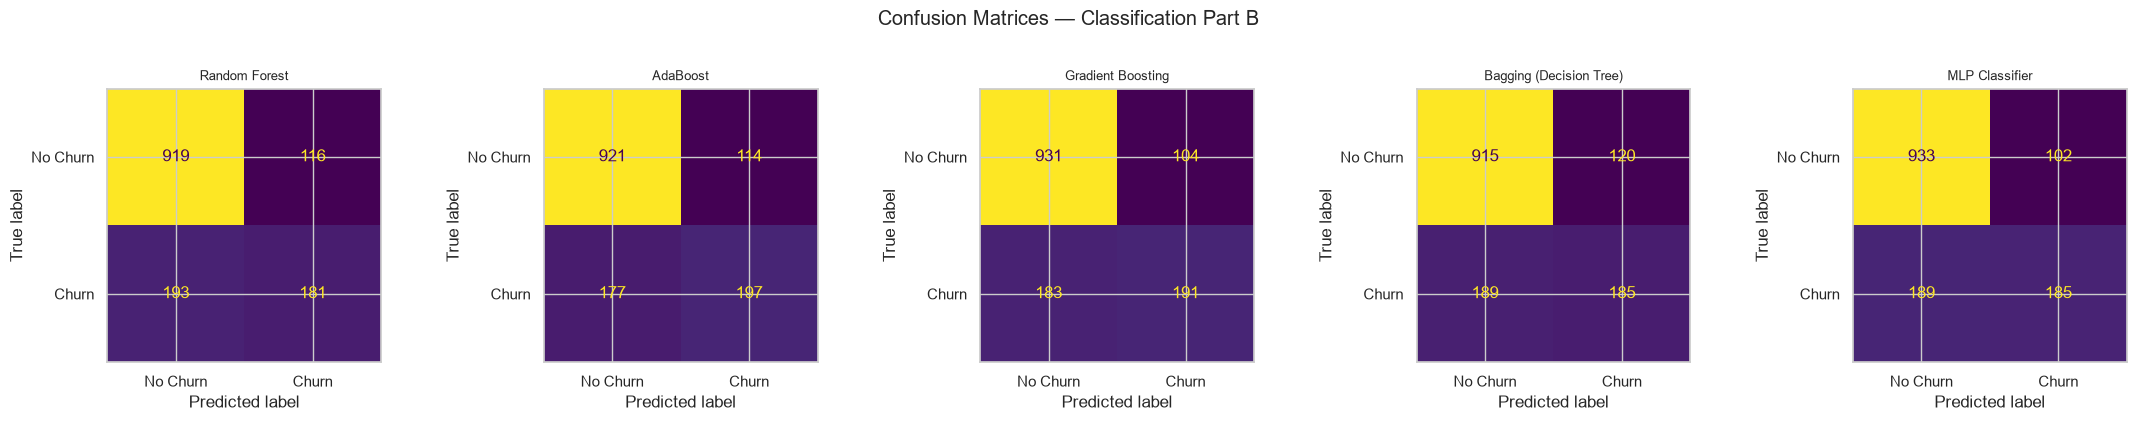

In [12]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, name in zip(axes, models_partB):
    cm = confusion_matrix(y_test, fitted[name].predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=['No Churn', 'Churn']).plot(ax=ax, colorbar=False)
    ax.set_title(name.split('. ')[1], fontsize=9)
plt.suptitle('Confusion Matrices — Classification Part B', y=1.03)
plt.tight_layout()
plt.show()

### ROC curves — Part B

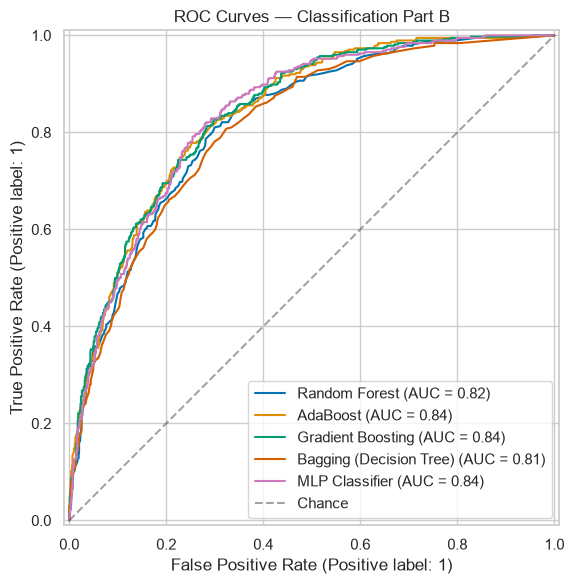

In [13]:
plt.figure(figsize=(7, 6))
for name in models_partB:
    RocCurveDisplay.from_predictions(y_test, probas[name], name=name.split('. ')[1], ax=plt.gca())
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Chance')
plt.title('ROC Curves — Classification Part B')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 5. Feature Importance (Random Forest & Gradient Boosting)
Importances are mapped back to readable feature names from the fitted preprocessor.

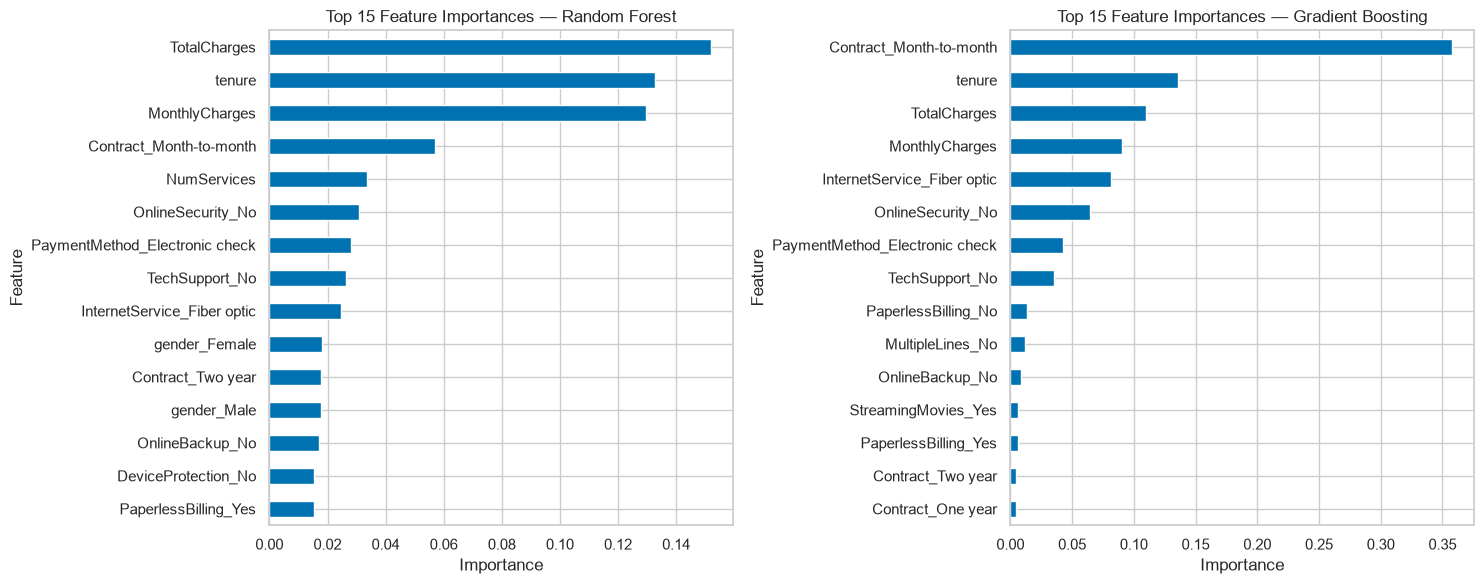

In [14]:
feat_names = fitted['6. Random Forest'].named_steps['prep'].get_feature_names_out()
feat_names = [n.replace('num__', '').replace('cat__', '') for n in feat_names]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, name in zip(axes, ['6. Random Forest', '8. Gradient Boosting']):
    imp = pd.Series(fitted[name].named_steps['model'].feature_importances_, index=feat_names)
    imp.nlargest(15).sort_values().plot(kind='barh', ax=ax, color='#0072B2')
    ax.set_title(f'Top 15 Feature Importances — {name.split(". ")[1]}')
    ax.set_xlabel('Importance')
    ax.set_ylabel('Feature')
plt.tight_layout()
plt.show()

## 6. Deliverable D6 / Rubric A2 — Consolidated 10-Algorithm Comparison
Single table: all ten algorithms, same preprocessing, same stratified 80:20 test split, ranked by weighted F1.

In [15]:
all_results = pd.DataFrame(results + partB_results)
all_results['Part'] = ['A'] * 5 + ['B'] * 5
all_results = (all_results.sort_values('F1 (weighted)', ascending=False)
                          .reset_index(drop=True))
all_results.index = all_results.index + 1
all_results.index.name = 'Rank'
style_table(all_results[['Algorithm', 'Part', 'Accuracy', 'Precision', 'Recall',
                       'F1 (weighted)', 'ROC-AUC']].reset_index())

,Rank,Algorithm,Part,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC
0,1,1. Logistic Regression,A,0.8062,0.7988,0.8062,0.8011,0.8418
1,2,8. Gradient Boosting,B,0.7963,0.7858,0.7963,0.7880,0.8398
2,3,7. AdaBoost,B,0.7935,0.7843,0.7935,0.7870,0.8386
3,4,10. MLP Classifier,B,0.7935,0.7819,0.7935,0.7840,0.8380
4,5,4. Decision Tree Classifier,A,0.7921,0.7813,0.7921,0.7838,0.8350
5,6,5. Support Vector Machine (SVC),A,0.7913,0.7793,0.7913,0.7814,0.7940
6,7,2. K-Nearest Neighbors,A,0.7743,0.7721,0.7743,0.7731,0.8117
7,8,9. Bagging (Decision Tree),B,0.7807,0.7698,0.7807,0.7731,0.8125
8,9,6. Random Forest,B,0.7807,0.7688,0.7807,0.7720,0.8216
9,10,3. Naive Bayes (Gaussian),A,0.6948,0.7965,0.6948,0.7127,0.8068


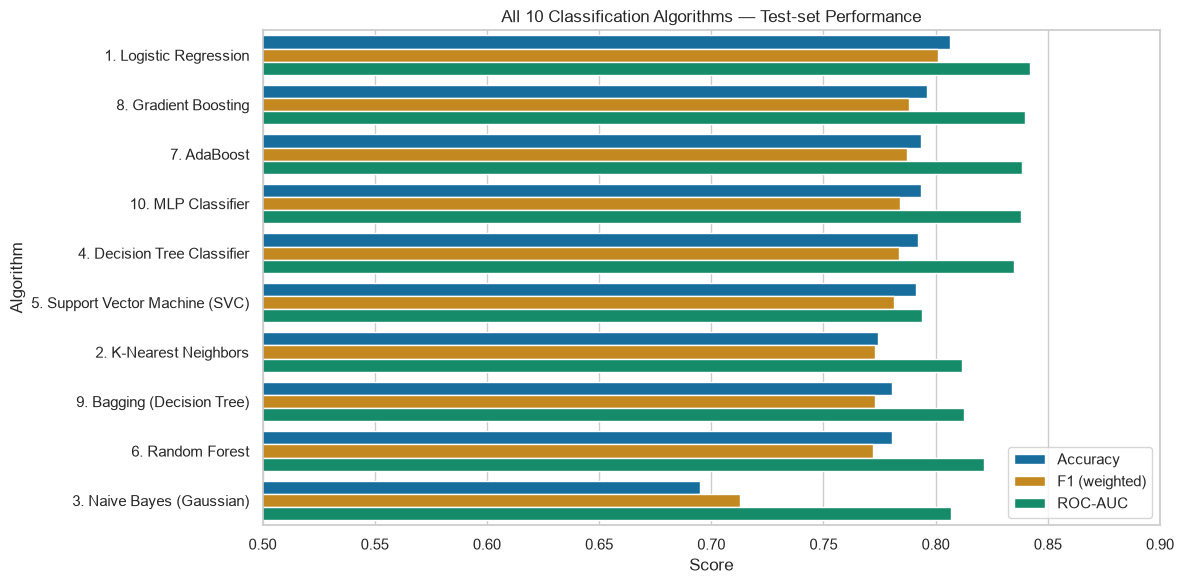

In [16]:
# Visual comparison of all 10 algorithms
plot_df = all_results.melt(id_vars='Algorithm',
                           value_vars=['Accuracy', 'F1 (weighted)', 'ROC-AUC'],
                           var_name='Metric', value_name='Score')
plt.figure(figsize=(12, 6))
sns.barplot(data=plot_df, y='Algorithm', x='Score', hue='Metric', palette='colorblind')
plt.title('All 10 Classification Algorithms — Test-set Performance')
plt.xlabel('Score')
plt.ylabel('Algorithm')
plt.xlim(0.5, 0.9)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

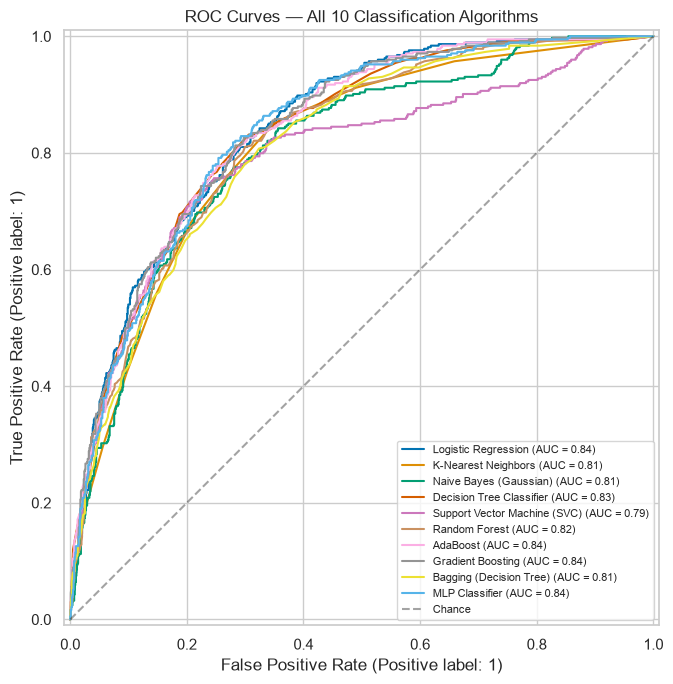

In [17]:
# All 10 ROC curves on one plot
plt.figure(figsize=(8, 7))
for name in list(models_partA) + list(models_partB):
    RocCurveDisplay.from_predictions(y_test, probas[name], name=name.split('. ')[1], ax=plt.gca())
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Chance')
plt.title('ROC Curves — All 10 Classification Algorithms')
plt.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

## 7. Cross-Validation of the Two Best Models
Guideline 7.2 requires cross-validation for at least the two best-performing models. We use
**stratified 5-fold CV on the training set only** (the test set stays untouched), with the full
pipeline inside each fold so scaling/encoding are re-fitted per fold. Models are ranked by weighted F1;
if you prefer ROC-AUC as the headline metric, change `rank_metric` below.

In [18]:
rank_metric = 'F1 (weighted)'
top2 = all_results.sort_values(rank_metric, ascending=False)['Algorithm'].head(2).tolist()
print('Top-2 models by', rank_metric, ':', top2)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name in top2:
    pipe = fitted[name]
    f1_cv = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='f1_weighted', n_jobs=-1)
    auc_cv = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='roc_auc', n_jobs=-1)
    cv_rows.append({'Algorithm': name,
                    'CV F1 mean': f1_cv.mean(), 'CV F1 std': f1_cv.std(),
                    'CV ROC-AUC mean': auc_cv.mean(), 'CV ROC-AUC std': auc_cv.std()})
cv_df = pd.DataFrame(cv_rows)
cv_df.style.format({c: '{:.4f}' for c in cv_df.columns if c != 'Algorithm'})

Top-2 models by F1 (weighted) : ['1. Logistic Regression', '8. Gradient Boosting']


,Algorithm,CV F1 mean,CV F1 std,CV ROC-AUC mean,CV ROC-AUC std
0,1. Logistic Regression,0.7958,0.0128,0.8462,0.0126
1,8. Gradient Boosting,0.7937,0.0126,0.8460,0.0122


## 8. Hyperparameter Tuning (GridSearchCV)
Tuning is run on the **training set only** using stratified 5-fold CV, optimising weighted F1.
Grids follow the assignment notes:

- **Random Forest:** `n_estimators` (+ depth / min leaf to control overfitting)
- **AdaBoost:** `n_estimators` and `learning_rate`
- **Gradient Boosting:** `learning_rate`, `n_estimators`, `max_depth`
- **MLP:** `hidden_layer_sizes` and `activation`

Grids are kept small so the notebook runs in a reasonable time; widen them if you have time.

In [19]:
param_grids = {
    '6. Random Forest': (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), {
        'model__n_estimators': [100, 200, 400],
        'model__max_depth': [None, 8, 12],
        'model__min_samples_leaf': [1, 3, 5]}),
    '7. AdaBoost': (AdaBoostClassifier(random_state=RANDOM_STATE), {
        'model__n_estimators': [50, 100, 200],
        'model__learning_rate': [0.05, 0.1, 0.5, 1.0]}),
    '8. Gradient Boosting': (GradientBoostingClassifier(random_state=RANDOM_STATE), {
        'model__n_estimators': [100, 150, 250],
        'model__learning_rate': [0.03, 0.05, 0.1],
        'model__max_depth': [2, 3, 4]}),
    '10. MLP Classifier': (MLPClassifier(max_iter=500, early_stopping=True, random_state=RANDOM_STATE), {
        'model__hidden_layer_sizes': [(32,), (64,), (64, 32), (128, 64)],
        'model__activation': ['relu', 'tanh'],
        'model__alpha': [1e-4, 1e-2]}),
}

tuned, tuning_rows = {}, []
for name, (est, grid) in param_grids.items():
    pipe = Pipeline([('prep', preprocessor), ('model', est)])
    gs = GridSearchCV(pipe, grid, scoring='f1_weighted', cv=skf, n_jobs=-1)
    gs.fit(X_train, y_train)
    row, _, proba = evaluate_model(name + ' (tuned)', gs.best_estimator_.named_steps['model'],
                                   X_train, y_train, X_test, y_test)
    tuned[name] = gs.best_estimator_
    probas[name + ' (tuned)'] = gs.best_estimator_.predict_proba(X_test)[:, 1]
    tuned_preds = gs.best_estimator_.predict(X_test)
    tuning_rows.append({
        'Algorithm': name,
        'Best params': {k.replace('model__', ''): v for k, v in gs.best_params_.items()},
        'CV F1 (best)': gs.best_score_,
        'Test F1 before': all_results.loc[all_results['Algorithm'] == name, 'F1 (weighted)'].iloc[0],
        'Test F1 after': f1_score(y_test, tuned_preds, average='weighted'),
        'Test ROC-AUC before': all_results.loc[all_results['Algorithm'] == name, 'ROC-AUC'].iloc[0],
        'Test ROC-AUC after': roc_auc_score(y_test, probas[name + ' (tuned)']),
    })
    print(f'Tuned {name}: best CV F1 = {gs.best_score_:.4f}')

tuning_df = pd.DataFrame(tuning_rows)
tuning_df['F1 change'] = tuning_df['Test F1 after'] - tuning_df['Test F1 before']
tuning_df['ROC-AUC change'] = tuning_df['Test ROC-AUC after'] - tuning_df['Test ROC-AUC before']
tuning_df

Tuned 6. Random Forest: best CV F1 = 0.7960
Tuned 7. AdaBoost: best CV F1 = 0.7980
Tuned 8. Gradient Boosting: best CV F1 = 0.7977
Tuned 10. MLP Classifier: best CV F1 = 0.7957


,Algorithm,Best params,CV F1 (best),Test F1 before,Test F1 after,Test ROC-AUC before,Test ROC-AUC after,F1 change,ROC-AUC change
0,6. Random Forest,"{'max_depth': 12, 'min_samples_leaf': 5, 'n_es...",0.795995,0.772045,0.787104,0.821629,0.841412,0.015059,0.019782
1,7. AdaBoost,"{'learning_rate': 0.5, 'n_estimators': 200}",0.797979,0.787023,0.796818,0.838624,0.842557,0.009794,0.003933
2,8. Gradient Boosting,"{'learning_rate': 0.03, 'max_depth': 3, 'n_est...",0.797727,0.788027,0.796907,0.839775,0.845568,0.008880,0.005793
3,10. MLP Classifier,"{'activation': 'relu', 'alpha': 0.01, 'hidden_...",0.795698,0.784044,0.790697,0.837983,0.841874,0.006653,0.003891


**Reading the tuning table:** "before" = Section 4 settings, "after" = best grid-search parameters, both scored on the
same untouched test set. A small or even negative test change is a legitimate finding (the grid was
chosen using CV on the training data, so test scores can move either way) — report it honestly rather than only
quoting improvements.

## 9. Section A3 — Final Model Selection
The final table includes the 10 baseline models plus the tuned Part-B models. The winner is chosen on
**weighted F1 and ROC-AUC**, with a look at the confusion matrix for churn recall, given the ~26/74 class imbalance.

In [20]:
tuned_rows = []
for name in tuned:
    r = tuning_df[tuning_df['Algorithm'] == name].iloc[0]
    tuned_rows.append({'Algorithm': name + ' (tuned)',
                       'Accuracy': accuracy_score(y_test, tuned[name].predict(X_test)),
                       'Precision': precision_score(y_test, tuned[name].predict(X_test), average='weighted'),
                       'Recall': recall_score(y_test, tuned[name].predict(X_test), average='weighted'),
                       'F1 (weighted)': r['Test F1 after'],
                       'ROC-AUC': r['Test ROC-AUC after']})

final_df = (pd.concat([all_results[['Algorithm', 'Accuracy', 'Precision', 'Recall', 'F1 (weighted)', 'ROC-AUC']],
                       pd.DataFrame(tuned_rows)])
            .sort_values(['F1 (weighted)', 'ROC-AUC'], ascending=False).reset_index(drop=True))
final_df.index += 1
final_df.index.name = 'Rank'
display(style_table(final_df.reset_index()))

best_name = final_df.iloc[0]['Algorithm']
print('\nSelected final model:', best_name)

,Rank,Algorithm,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC
0,1,1. Logistic Regression,0.8062,0.7988,0.8062,0.8011,0.8418
1,2,8. Gradient Boosting (tuned),0.8062,0.7959,0.8062,0.7969,0.8456
2,3,7. AdaBoost (tuned),0.8034,0.7946,0.8034,0.7968,0.8426
3,4,10. MLP Classifier (tuned),0.8006,0.7894,0.8006,0.7907,0.8419
4,5,8. Gradient Boosting,0.7963,0.7858,0.7963,0.7880,0.8398
5,6,6. Random Forest (tuned),0.7970,0.7855,0.7970,0.7871,0.8414
6,7,7. AdaBoost,0.7935,0.7843,0.7935,0.7870,0.8386
7,8,10. MLP Classifier,0.7935,0.7819,0.7935,0.7840,0.8380
8,9,4. Decision Tree Classifier,0.7921,0.7813,0.7921,0.7838,0.8350
9,10,5. Support Vector Machine (SVC),0.7913,0.7793,0.7913,0.7814,0.7940



Selected final model: 1. Logistic Regression


              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



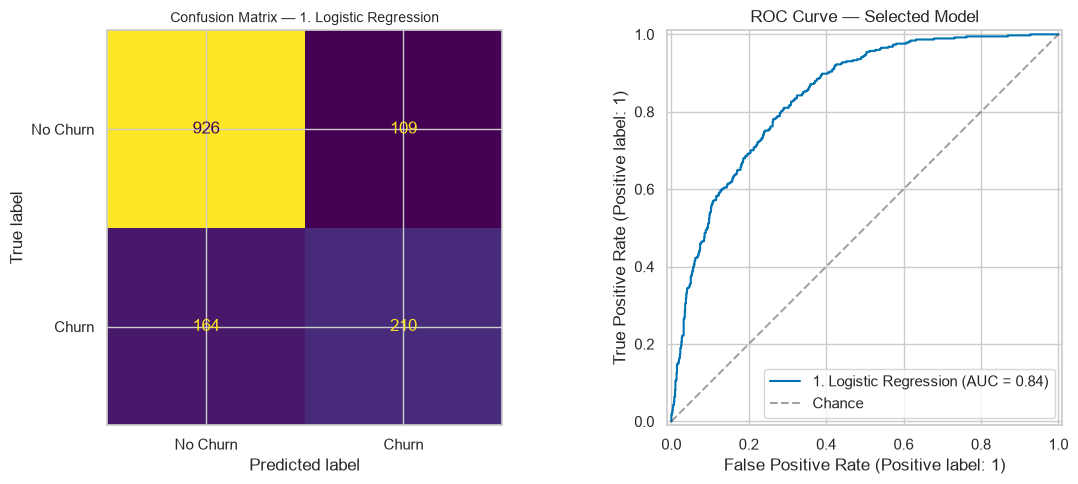

In [21]:
# Detailed report for the selected model
def get_pipe(name):
    if name.endswith('(tuned)'):
        return tuned[name.replace(' (tuned)', '')]
    return fitted[name]

best_pipe = get_pipe(best_name)
best_preds = best_pipe.predict(X_test)
print(classification_report(y_test, best_preds, target_names=['No Churn', 'Churn']))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, best_preds),
                       display_labels=['No Churn', 'Churn']).plot(ax=axes[0], colorbar=False)
axes[0].set_title(f'Confusion Matrix — {best_name}', fontsize=10)
RocCurveDisplay.from_predictions(y_test, best_pipe.predict_proba(X_test)[:, 1],
                                 name=best_name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Chance')
axes[1].set_title('ROC Curve — Selected Model')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

### Justification (fill in from YOUR actual output above)
Write 4–6 sentences in your own words (the guidelines require original interpretation). Cover:
1. **Which model won** and its weighted F1 / ROC-AUC versus the runner-up — is the gap meaningful compared with the CV standard deviation in Section 7?
2. **Which metric you prioritised and why** — with ~26% churn, accuracy alone is misleading; look at the churn-class recall in the report above.
3. **What tuning changed** — which metric improved and by how much (Section 8 table), or why it didn't.
4. **Trade-offs** — e.g. interpretability (Logistic Regression) vs. performance (boosting), training time, overfitting risk.
5. **Business reading** — which errors are costlier here: missed churners (false negatives) or wrongly flagged loyal customers (false positives)?

*Expect to be asked in the viva: why boosting vs. bagging differ (sequential error-correction vs. parallel variance reduction), why Naive Bayes' independence assumption is violated on this data, and why scaling matters for MLP/SVM/KNN but not for tree ensembles.*

## 10. Save the Final Model (for the optional GUI / deployment bonus)

In [22]:
import os
os.makedirs('../models', exist_ok=True)
joblib.dump(best_pipe, '../models/churn_best_model.pkl')
print('Saved ->', '../models/churn_best_model.pkl')

# Quick sanity check: the saved pipeline accepts raw (un-encoded) rows
loaded = joblib.load('../models/churn_best_model.pkl')
print('Sample prediction (1 = churn):', loaded.predict(X_test.iloc[:3]))

Saved -> ../models/churn_best_model.pkl
Sample prediction (1 = churn): [0 1 0]
